<a href="https://colab.research.google.com/github/A-I-eXplorers/ShimSoen/blob/main/Data_Preprocessing/Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import seaborn as sns
titanic = sns.load_dataset('titanic')

In [2]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


891개의 index가 있다는데 보면 891개를 못채운 non-null count가 있는 것으로 보아 null값을 가지고 있음을 확인

In [3]:
titanic.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


데이터 속성값의 이상 여부 확인

<Axes: >

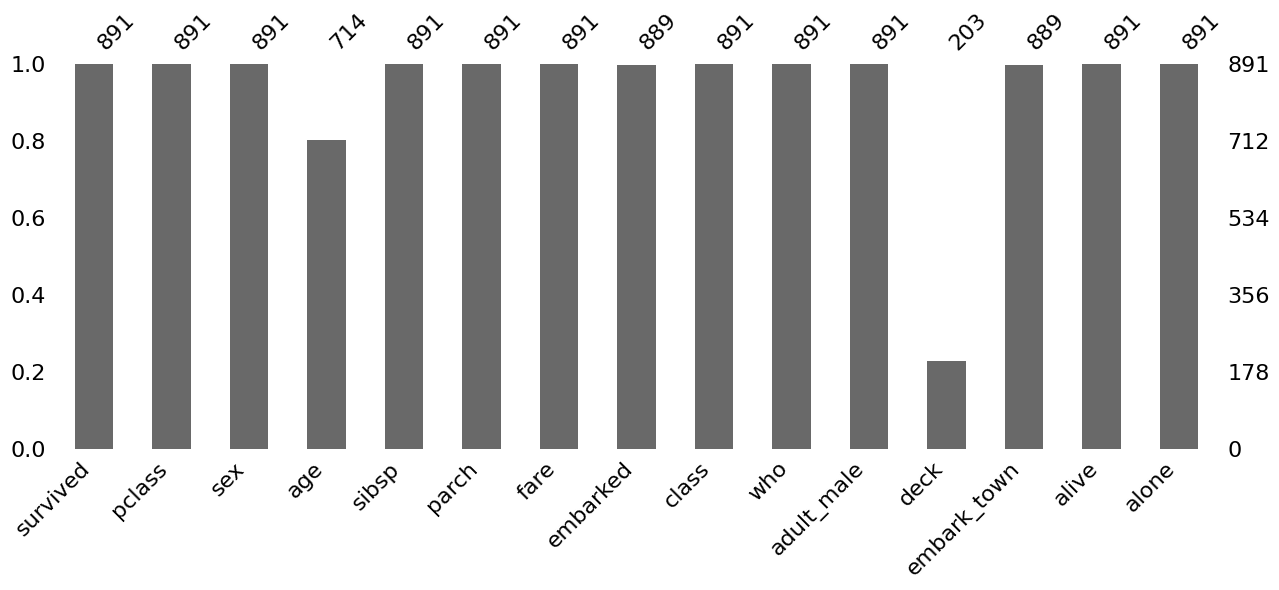

In [4]:
import missingno as msno
msno.bar(titanic, figsize=(15, 5))

# 생존한 인원 확인

In [5]:
titanic['survived'].value_counts()

,count
survived,
0,549
1,342


#최소 전처리

In [6]:
titanic['age'] = titanic['age'].fillna(titanic['age'].median())
titanic['age'].isnull().sum()

np.int64(0)

중간값으로 채운 이유가 이상치가 있을 수 있어서 평균값보단 중앙값으로 잡는 것이 좋다고 판단

In [7]:
titanic['sex'] = titanic['sex'].map({'male': 0, 'female': 1})

성별의 dtye이 object여서 나중에 계산하기 위해 미리 숫자로 변경

In [8]:
titanic.groupby('sex').mean(numeric_only=True)

,survived,pclass,age,sibsp,parch,fare,adult_male,alone
sex,,,,,,,,
0,0.188908,2.389948,30.140676,0.429809,0.235702,25.523893,0.930676,0.712305
1,0.742038,2.159236,27.929936,0.694268,0.649682,44.479818,0.000000,0.401274


1(female)인 경우가 생존률이 더 높음을 확인

<Axes: xlabel='age'>

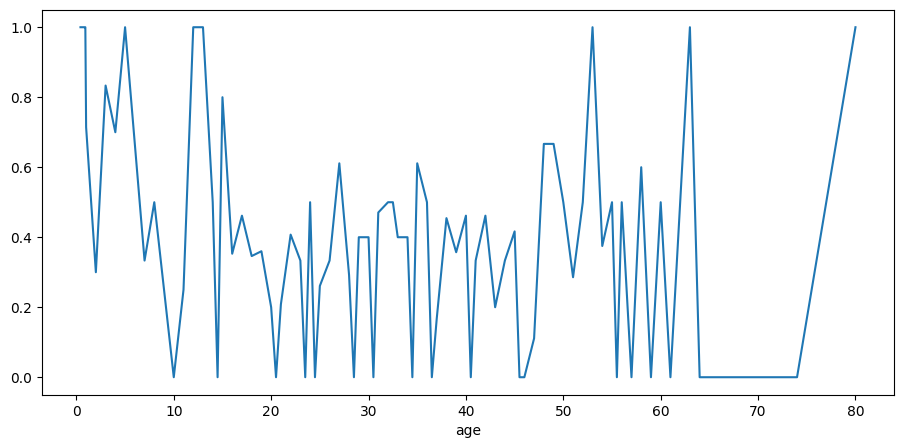

In [9]:
titanic.groupby('age').mean(numeric_only=True)['survived'].plot(figsize=(11,5))

승객 연령대별 생존 평균 시각화